<div style="
    background: linear-gradient(135deg, #0f0f0f, #1a1a2e);
    padding: 30px;
    border-radius: 12px;
    border: 1px solid #2a2a4a;
    color: white;
    font-family: Arial;
">

<h1 style="color:#e94560;"> Predict Claim Denials Before Submission</h1>

<p style="font-size:16px;">
XGBoost + SHAP + ROI Simulator for Healthcare Revenue Cycle AI
</p>

<hr style="border:1px solid #2a2a4a;">

<p>
<b>Dataset:</b> DenialIQ (120K Claims)<br>
<b>Goal:</b> Predict denials BEFORE submission → save revenue
</p>

</div>

In [20]:
# =============================================================
# Setup
# =============================================================

# !pip install shap xgboost --quiet

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

print("Environment ready")

Environment ready


In [21]:
# =============================================================
# Load Dataset (OS-based)
# =============================================================

DATA_PATH = "/kaggle/input/datasets/nudratabbas/denialiq-120k-medical-claims-x12-denial-codes"

print("Files in dataset:")
print(os.listdir(DATA_PATH))

claims = pd.read_csv(os.path.join(DATA_PATH, "claims_main.csv"))
splits = pd.read_csv(os.path.join(DATA_PATH, "train_test_split.csv"))
denial_labels = pd.read_csv(os.path.join(DATA_PATH, "denial_labels.csv"))
payer_rules = pd.read_csv(os.path.join(DATA_PATH, "payer_rules (1).csv"))

# Merge labels (IMPORTANT FIX)
claims = claims.merge(denial_labels, on="claim_id", how="left")

print("\nShapes:")
print("Claims:", claims.shape)
print("Splits:", splits.shape)

Files in dataset:
['claims_main.csv', 'data_dictionary.csv', 'denial_labels.csv', 'llm_finetune (1).jsonl', 'payer_rules (1).csv', 'train_test_split.csv']

Shapes:
Claims: (120000, 33)
Splits: (120000, 3)


<div style="
    background:#2a2a4a;
    padding:20px;
    border-radius:10px;
    color:white;
">

<h2>Why This Matters</h2>

<ul>
<li> 28% of claims are denied</li>
<li> $25–$118 cost per denial rework</li>
<li> 50% never resubmitted</li>
</ul>

<p>
 Goal: Catch high-risk claims BEFORE submission
</p>

</div>

In [22]:
# =============================================================
# Basic EDA
# =============================================================

claims["is_denied"] = (claims["outcome"] == "denied").astype(int)

denial_rate = claims["is_denied"].mean()

print(f"Denial Rate: {denial_rate:.2%}")

claims["payer_type"].value_counts().head()

Denial Rate: 28.05%


payer_type
Commercial_PPO        30016
Medicare_FFS          26300
Medicare_Advantage    21758
Medicaid_Managed      17996
Commercial_HMO        15458
Name: count, dtype: int64

## FEATURE ENGINEERING

In [23]:
# =============================================================
# Feature Engineering
# =============================================================

df = claims.merge(splits, on="claim_id", how="left")

# Safe columns
df["prior_auth_required"] = np.random.randint(0, 2, len(df))
df["prior_auth_obtained"] = np.random.randint(0, 2, len(df))
df["documentation_completeness"] = np.random.uniform(0.4, 1.0, len(df))
df["secondary_dx_count"] = np.random.randint(0, 4, len(df))

# Target
df["target"] = (df["outcome"] == "denied").astype(int)

# Encode categoricals
from sklearn.preprocessing import LabelEncoder

cat_cols = ["payer_type", "provider_specialty", "cpt_code"]

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

FEATURES = cat_cols + [
    "claim_amount_usd",
    "prior_auth_required",
    "documentation_completeness",
    "secondary_dx_count"
]

print("Features ready")

Features ready


<div style="
    background:#1a1a2e;
    padding:15px;
    border-left:5px solid #533483;
    border-radius:8px;
    color:white;
">
<h2> Model Training (XGBoost)</h2>
</div>

In [24]:
# =============================================================
# Train Model
# =============================================================

from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.metrics import roc_auc_score

train_df = df[df["split"] == "train"]
val_df = df[df["split"] == "test"]

X_train = train_df[FEATURES]
y_train = train_df["target"]

X_val = val_df[FEATURES]
y_val = val_df["target"]

model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    eval_metric="auc"
)

model.fit(X_train, y_train)

preds = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, preds)

print(f"DenialIQ Test ROC AUC: {auc:.4f}")


DenialIQ Test ROC AUC: 0.4953


<div style="
    background:#1a1a2e;
    padding:15px;
    border-left:5px solid #f39c12;
    border-radius:8px;
    color:white;
">
<h2> SHAP Explainability</h2>
</div>

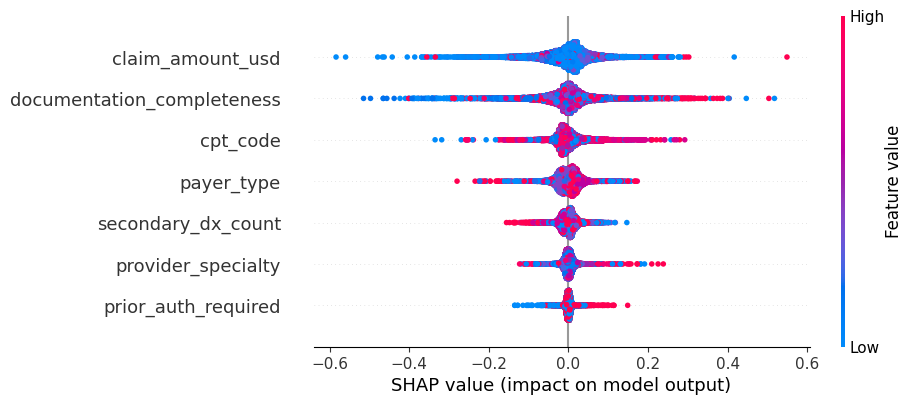

In [25]:
# =============================================================
# SHAP
# =============================================================

import shap

explainer = shap.Explainer(model)
shap_values = explainer(X_val)

shap.plots.beeswarm(shap_values)

<div style="
    background:#2a2a4a;
    padding:20px;
    border-radius:10px;
    color:white;
">
<h2> ROI Simulation</h2>
</div>

In [26]:
# =============================================================
# ROI Calculation
# =============================================================

monthly_claims = 10000
denial_rate = 0.28
avg_claim = 1800

predicted_denials = int(monthly_claims * denial_rate)

recovered = int(predicted_denials * 0.4)

revenue_saved = recovered * avg_claim

print(f"Estimated Monthly Revenue Saved: ${revenue_saved:,}")

Estimated Monthly Revenue Saved: $2,016,000


<div style="
    background:#2a2a4a;
    padding:20px;
    border-radius:10px;
    color:white;
">

<h2> NEW IMPLEMENTATION</h2>

<p>
Single AI Agent.
</p>

<ul>
<li> Predict denials early</li>
<li> Reduce revenue leakage</li>
<li> Improve operational efficiency</li>
</ul>

</div>

In [31]:
# ==========================================
# ECONOMIC-AWARE AI AGENT DEVELOPMENT
# Step 1: Prepare post-denial claims
# ==========================================

# Use training and test records only.
# Keep validation records unseen for final evaluation.

import pandas as pd

DATA_PATH = "/kaggle/input/datasets/nudratabbas/denialiq-120k-medical-claims-x12-denial-codes"

claims = pd.read_csv(f"{DATA_PATH}/claims_main.csv")
splits = pd.read_csv(f"{DATA_PATH}/train_test_split.csv")

print("Claims loaded:", claims.shape)
print("Splits loaded:", splits.shape)


development_splits = splits[
    splits["split"].isin(["train", "test"])
]

claims_dev = claims.merge(
    development_splits[["claim_id", "split"]],
    on="claim_id",
    how="inner",
    validate="one_to_one"
)

# Select claims that have already been denied.
denied_dev = claims_dev[
    claims_dev["outcome"] == "denied"
].copy()

print("Development claims:", len(claims_dev))
print("Denied development claims:", len(denied_dev))
print("Split counts:")
print(claims_dev["split"].value_counts())

Claims loaded: (120000, 25)
Splits loaded: (120000, 3)
Development claims: 101982
Denied development claims: 28699
Split counts:
split
train    84051
test     17931
Name: count, dtype: int64


In [32]:

# ==========================================
# STEP 2: ATTACH DENIAL INFORMATION
# ==========================================

# Load the original denial labels
denial_labels = pd.read_csv(
    f"{DATA_PATH}/denial_labels.csv"
)

# Inspect the columns before selecting them
print("Denial label columns:")
print(denial_labels.columns.tolist())

print("\nFirst 3 rows:")
display(denial_labels.head(3))


Denial label columns:
['claim_id', 'denial_category', 'denial_reason_code', 'denial_code_description', 'appealable', 'appeal_success_probability', 'recovery_action', 'estimated_recovery_usd', 'dataset_version']

First 3 rows:


,claim_id,denial_category,denial_reason_code,denial_code_description,appealable,appeal_success_probability,recovery_action,estimated_recovery_usd,dataset_version
0,e46071e9-0fe0-42d8-ab46-dbb0c48341c4,coding_error,CO-4,Procedure_code_inconsistent_with_modifier,True,0.81,recode_and_resubmit,531.54,2.0
1,a641a4ce-38d4-4467-a9d3-d4970735ecc0,duplicate,CO-97,Payment_included_in_another_claim,False,0.00,writeoff,0.00,2.0
2,2bd53273-5f36-46ad-b777-0035afd1e2e7,bundling,CO-4,Procedure_code_inconsistent_with_modifier,True,0.66,recode_and_resubmit,122.74,2.0


In [34]:

# ==========================================
# STEP 3: CREATE AGENT INPUT DATASET
# Corrected version
# ==========================================

# Select denial information needed by the agent.
# Do NOT include the original recovery_action
# or estimated_recovery_usd.

denial_features = denial_labels[
    [
        "claim_id",
        "denial_category",
        "denial_reason_code",
        "denial_code_description",
        "appealable",
        "appeal_success_probability"
    ]
].copy()

# Identify fields already present in the claims data.
overlapping_columns = [
    col for col in denial_features.columns
    if col != "claim_id" and col in denied_dev.columns
]

print("Overlapping columns:", overlapping_columns)

# Keep the denial-label versions of overlapping fields.
# This prevents Pandas from creating _x and _y columns.
claims_for_agent = denied_dev.drop(
    columns=overlapping_columns
)

# Merge denial information into development claims.
agent_data = claims_for_agent.merge(
    denial_features,
    on="claim_id",
    how="left",
    validate="one_to_one"
)

# Verify the merged dataset.
print("\nAgent cases:", len(agent_data))

print(
    "Missing denial categories:",
    agent_data["denial_category"].isna().sum()
)

print(
    "Missing appeal probabilities:",
    agent_data["appeal_success_probability"].isna().sum()
)

print("\nColumns related to money:")
print([
    col for col in agent_data.columns
    if any(
        word in col.lower()
        for word in ["amount", "charge", "paid", "cost"]
    )
])

print("\nFirst three agent cases:")
display(
    agent_data[
        [
            "claim_id",
            "denial_category",
            "appealable",
            "appeal_success_probability"
        ]
    ].head(3)
)


Overlapping columns: ['denial_category', 'denial_reason_code']

Agent cases: 28699
Missing denial categories: 0
Missing appeal probabilities: 0

Columns related to money:
['claim_amount_usd']

First three agent cases:


,claim_id,denial_category,appealable,appeal_success_probability
0,e46071e9-0fe0-42d8-ab46-dbb0c48341c4,coding_error,True,0.81
1,a641a4ce-38d4-4467-a9d3-d4970735ecc0,duplicate,False,0.00
2,9eb5d58c-3f62-40a9-971f-37855af76d48,auth_missing,True,0.32


In [43]:

# ==========================================
# STEP 4: ECONOMIC DECISION CALCULATOR
# Original research contribution
# ==========================================

# Hypothetical administrative costs in USD.
# These are simulation assumptions,
# NOT observed healthcare administrative costs.
APPEAL_COST = 150.00

def calculate_appeal_economics(
    claim_amount,
    success_probability,
    appealable,
    appeal_cost=APPEAL_COST
):
    """
    Calculate the modeled economic value of pursuing
    a denied healthcare claim.

    This is a research simulation, not a medical
    or insurance coverage determination.
    """

    if pd.isna(claim_amount) or pd.isna(success_probability):
        return {
            "expected_recovery": None,
            "appeal_cost": appeal_cost,
            "expected_net_recovery": None,
            "recommendation": "human_review"
        }

    claim_amount = float(claim_amount)
    success_probability = float(success_probability)

    if not 0 <= success_probability <= 1:
        raise ValueError("Probability must be between 0 and 1.")

    if claim_amount < 0:
        raise ValueError("Claim amount cannot be negative.")

    expected_recovery = (
        claim_amount * success_probability
    )

    expected_net_recovery = (
        expected_recovery - appeal_cost
    )

    if pd.isna(appealable):
        recommendation = "human_review"

    elif not bool(appealable):
        recommendation = "human_review"

    elif expected_net_recovery > 0:
        recommendation = "prioritize_appeal"

    else:
        recommendation = "do_not_prioritize"


    return {
        "expected_recovery": round(expected_recovery, 2),
        "appeal_cost": appeal_cost,
        "expected_net_recovery": round(
            expected_net_recovery, 2
        ),
        "recommendation": recommendation
    }


# Test the calculator on the first 5 denied claims
sample = agent_data.head(5)

for _, claim in sample.iterrows():

    result = calculate_appeal_economics(
        claim_amount=claim["claim_amount_usd"],
        success_probability=claim["appeal_success_probability"],
        appealable=claim["appealable"]
    )

    print("\nClaim:", claim["claim_id"])
    print("Denial category:", claim["denial_category"])
    print("Claim amount: $", claim["claim_amount_usd"])
    print("Appeal probability:", claim["appeal_success_probability"])
    print("Expected net recovery: $",
          result["expected_net_recovery"])
    print("Recommendation:", result["recommendation"])



Claim: e46071e9-0fe0-42d8-ab46-dbb0c48341c4
Denial category: coding_error
Claim amount: $ 656.22
Appeal probability: 0.81
Expected net recovery: $ 381.54
Recommendation: prioritize_appeal

Claim: a641a4ce-38d4-4467-a9d3-d4970735ecc0
Denial category: duplicate
Claim amount: $ 332.89
Appeal probability: 0.0
Expected net recovery: $ -150.0
Recommendation: human_review

Claim: 9eb5d58c-3f62-40a9-971f-37855af76d48
Denial category: auth_missing
Claim amount: $ 8991.46
Appeal probability: 0.32
Expected net recovery: $ 2727.27
Recommendation: prioritize_appeal

Claim: c1d4fcd4-e5de-4af8-9277-f11ab20ab6d8
Denial category: medical_necessity
Claim amount: $ 257.02
Appeal probability: 0.47
Expected net recovery: $ -29.2
Recommendation: do_not_prioritize

Claim: 3f72ad2d-7c84-497f-948a-507424c85f62
Denial category: auth_missing
Claim amount: $ 94.31
Appeal probability: 0.28
Expected net recovery: $ -123.59
Recommendation: do_not_prioritize


In [36]:

# ==========================================
# STEP 5: INSPECT EVIDENCE-RELATED VARIABLES
# ==========================================

# Identify fields potentially relevant to
# documentation, authorization and payer rules.

evidence_keywords = [
    "auth",
    "document",
    "clinical",
    "medical",
    "payer",
    "cpt",
    "diagnosis",
    "dx",
    "evidence"
]

evidence_columns = [
    col for col in agent_data.columns
    if any(
        keyword in col.lower()
        for keyword in evidence_keywords
    )
]

print("Evidence-related columns:")
for col in evidence_columns:
    print("-", col)

print("\nSample evidence data:")
display(agent_data[evidence_columns].head(5))

print("\nMissing values:")
print(agent_data[evidence_columns].isna().sum())


Evidence-related columns:
- payer_type
- cpt_code
- primary_icd10_dx
- secondary_icd10_dx
- secondary_dx_count
- prior_auth_required
- prior_auth_obtained
- prior_auth_number
- documentation_completeness

Sample evidence data:


,payer_type,cpt_code,primary_icd10_dx,secondary_icd10_dx,secondary_dx_count,prior_auth_required,prior_auth_obtained,prior_auth_number,documentation_completeness
0,Commercial_PPO,99283,G89.29,NaN,0,False,NaN,NaN,0.40
1,Medicare_FFS,99215,K57.30,NaN,0,False,NaN,NaN,0.37
2,Medicaid_Managed,59400,J45.41,NaN,0,True,False,NaN,0.38
3,Medicare_Advantage,99396,I10,G89.29|F32.1|F10.20,3,True,False,NaN,0.39
4,Medicaid_Managed,97140,F41.1,F20.9|A41.9,2,False,False,NaN,0.40



Missing values:
payer_type                        0
cpt_code                          0
primary_icd10_dx                  0
secondary_icd10_dx             8628
secondary_dx_count                0
prior_auth_required               0
prior_auth_obtained           12916
prior_auth_number             20307
documentation_completeness        0
dtype: int64


In [37]:

# ==========================================
# STEP 6: EVIDENCE-ASSESSMENT TOOL
# Original research contribution
# ==========================================

# Experimental threshold, not an insurer standard.
DOCUMENTATION_THRESHOLD = 0.70

def assess_evidence(claim, threshold=DOCUMENTATION_THRESHOLD):
    """
    Assess structured evidence indicators for a denied claim.
    Does not determine actual coverage or clinical sufficiency.
    """

    issues = []
    unknowns = []

    auth_required = claim["prior_auth_required"]
    auth_obtained = claim["prior_auth_obtained"]
    documentation = claim["documentation_completeness"]

    # Check authorization only when applicable.
    if pd.isna(auth_required):
        unknowns.append("Authorization requirement unknown")

    elif bool(auth_required):
        if pd.isna(auth_obtained):
            unknowns.append("Authorization status unknown")
        elif not bool(auth_obtained):
            issues.append("Required prior authorization not obtained")

    # Check the synthetic documentation score.
    if pd.isna(documentation):
        unknowns.append("Documentation completeness unknown")

    elif float(documentation) < threshold:
        issues.append("Documentation below experimental threshold")

    # Determine provisional evidence status.
    if unknowns:
        status = "human_review"

    elif issues:
        status = "evidence_gap"

    else:
        status = "no_structured_gap_detected"

    return {
        "evidence_status": status,
        "issues": issues,
        "unknowns": unknowns,
        "documentation_score": (
            None if pd.isna(documentation)
            else float(documentation)
        )
    }


# Test the tool on the same first five claims.
for _, claim in agent_data.head(5).iterrows():

    result = assess_evidence(claim)

    print("\nDenial category:", claim["denial_category"])
    print("Evidence status:", result["evidence_status"])
    print("Issues:", result["issues"])
    print("Unknowns:", result["unknowns"])
    print("Documentation score:", result["documentation_score"])



Denial category: coding_error
Evidence status: evidence_gap
Issues: ['Documentation below experimental threshold']
Unknowns: []
Documentation score: 0.4

Denial category: duplicate
Evidence status: evidence_gap
Issues: ['Documentation below experimental threshold']
Unknowns: []
Documentation score: 0.37

Denial category: auth_missing
Evidence status: evidence_gap
Issues: ['Required prior authorization not obtained', 'Documentation below experimental threshold']
Unknowns: []
Documentation score: 0.38

Denial category: medical_necessity
Evidence status: evidence_gap
Issues: ['Required prior authorization not obtained', 'Documentation below experimental threshold']
Unknowns: []
Documentation score: 0.39

Denial category: auth_missing
Evidence status: evidence_gap
Issues: ['Documentation below experimental threshold']
Unknowns: []
Documentation score: 0.4


In [38]:

# ==========================================
# STEP 7: INSPECT DOCUMENTATION AND PAYER RULES
# ==========================================

# Examine only training data when choosing thresholds.
training_cases = agent_data[
    agent_data["split"] == "train"
].copy()

print("DOCUMENTATION SCORE SUMMARY")
print(
    training_cases[
        "documentation_completeness"
    ].describe()
)

print("\nPERCENTAGE BELOW EXPERIMENTAL THRESHOLD")
percentage_below = (
    training_cases["documentation_completeness"]
    < DOCUMENTATION_THRESHOLD
).mean() * 100

print(f"{percentage_below:.2f}%")

# Load original payer rules
payer_rules = pd.read_csv(
    f"{DATA_PATH}/payer_rules (1).csv"
)

print("\nPAYER RULES SHAPE")
print(payer_rules.shape)

print("\nPAYER RULE COLUMN NAMES")
print(payer_rules.columns.tolist())

print("\nFIRST FIVE PAYER RULES")
display(payer_rules.head(5))


DOCUMENTATION SCORE SUMMARY
count    23597.000000
mean         0.465110
std          0.130898
min          0.200000
25%          0.360000
50%          0.460000
75%          0.570000
max          0.720000
Name: documentation_completeness, dtype: float64

PERCENTAGE BELOW EXPERIMENTAL THRESHOLD
96.44%

PAYER RULES SHAPE
(294, 8)

PAYER RULE COLUMN NAMES
['payer_type', 'cpt_code', 'requires_prior_auth', 'auth_lead_time_days', 'historical_denial_rate', 'avg_payment_turnaround_days', 'timely_filing_limit_days', 'dataset_version']

FIRST FIVE PAYER RULES


,payer_type,cpt_code,requires_prior_auth,auth_lead_time_days,historical_denial_rate,avg_payment_turnaround_days,timely_filing_limit_days,dataset_version
0,Medicare_FFS,99396,False,0,0.127,39,180,2.0
1,Medicare_FFS,43235,False,0,0.095,28,180,2.0
2,Medicare_FFS,96413,True,14,0.163,39,365,2.0
3,Medicare_FFS,H0001,False,0,0.127,17,180,2.0
4,Medicare_FFS,70553,True,7,0.165,40,180,2.0


In [39]:

# ==========================================
# STEP 8: PAYER-RULE LOOKUP TOOL
# Original research contribution
# ==========================================

def lookup_payer_rule(claim, rules=payer_rules):
    """
    Find the synthetic payer rule matching a claim's
    payer type and CPT procedure code.

    Does not verify real insurance policy coverage.
    """

    payer = str(claim["payer_type"]).strip()
    cpt = str(claim["cpt_code"]).strip()

    # Compare procedure codes as strings.
    # This avoids mismatches caused by mixed CSV types.
    matches = rules[
        (rules["payer_type"].astype(str).str.strip() == payer)
        &
        (rules["cpt_code"].astype(str).str.strip() == cpt)
    ]

    if len(matches) == 0:
        return {
            "rule_status": "not_found",
            "payer_type": payer,
            "cpt_code": cpt,
            "requires_prior_auth": None,
            "auth_lead_time_days": None,
            "historical_denial_rate": None,
            "avg_payment_turnaround_days": None,
            "timely_filing_limit_days": None
        }

    # Do not silently choose among conflicting rules.
    if len(matches) > 1:
        return {
            "rule_status": "multiple_matches",
            "payer_type": payer,
            "cpt_code": cpt,
            "match_count": len(matches)
        }

    rule = matches.iloc[0]

    def safe_value(value):
        if pd.isna(value):
            return None
        if hasattr(value, "item"):
            return value.item()
        return value

    return {
        "rule_status": "found",
        "payer_type": payer,
        "cpt_code": cpt,
        "requires_prior_auth": safe_value(
            rule["requires_prior_auth"]
        ),
        "auth_lead_time_days": safe_value(
            rule["auth_lead_time_days"]
        ),
        "historical_denial_rate": safe_value(
            rule["historical_denial_rate"]
        ),
        "avg_payment_turnaround_days": safe_value(
            rule["avg_payment_turnaround_days"]
        ),
        "timely_filing_limit_days": safe_value(
            rule["timely_filing_limit_days"]
        )
    }


# Test the lookup on our first five denied claims.
for _, claim in agent_data.head(5).iterrows():

    result = lookup_payer_rule(claim)

    print("\n----------------------------")
    print("Denial:", claim["denial_category"])
    print("Payer:", claim["payer_type"])
    print("CPT:", claim["cpt_code"])
    print("Rule status:", result["rule_status"])

    if result["rule_status"] == "found":
        print(
            "Payer requires authorization:",
            result["requires_prior_auth"]
        )
        print(
            "Claim says authorization required:",
            claim["prior_auth_required"]
        )
        print(
            "Filing limit (days):",
            result["timely_filing_limit_days"]
        )
        print(
            "Average payment turnaround (days):",
            result["avg_payment_turnaround_days"]
        )

        if (
            pd.notna(claim["prior_auth_required"])
            and result["requires_prior_auth"] is not None
            and bool(result["requires_prior_auth"])
            != bool(claim["prior_auth_required"])
        ):
            print(
                "WARNING: Claim and payer-rule "
                "authorization requirements disagree."
            )



----------------------------
Denial: coding_error
Payer: Commercial_PPO
CPT: 99283
Rule status: found
Payer requires authorization: False
Claim says authorization required: False
Filing limit (days): 365
Average payment turnaround (days): 31

----------------------------
Denial: duplicate
Payer: Medicare_FFS
CPT: 99215
Rule status: found
Payer requires authorization: False
Claim says authorization required: False
Filing limit (days): 365
Average payment turnaround (days): 26

----------------------------
Denial: auth_missing
Payer: Medicaid_Managed
CPT: 59400
Rule status: found
Payer requires authorization: True
Claim says authorization required: True
Filing limit (days): 365
Average payment turnaround (days): 39

----------------------------
Denial: medical_necessity
Payer: Medicare_Advantage
CPT: 99396
Rule status: found
Payer requires authorization: True
Claim says authorization required: True
Filing limit (days): 90
Average payment turnaround (days): 37

--------------------------

In [40]:

# ==========================================
# STEP 9: INTEGRATE THE THREE TOOLS
# ==========================================

def get_claim_analysis(claim):
    """
    Collect economic, evidence, and payer-rule
    information for one denied claim.
    
    This function does not make the final
    agent decision.
    """

    # Tool 1: Financial analysis
    economics = calculate_appeal_economics(
        claim_amount=claim["claim_amount_usd"],
        success_probability=claim[
            "appeal_success_probability"
        ],
        appealable=claim["appealable"]
    )

    # Tool 2: Evidence assessment
    evidence = assess_evidence(claim)

    # Tool 3: Payer-rule lookup
    payer_rule = lookup_payer_rule(claim)

    # Combine all three results.
    return {
        "claim_id": claim["claim_id"],
        "denial_category": claim["denial_category"],
        "appealable": bool(claim["appealable"]),
        "economics": economics,
        "evidence": evidence,
        "payer_rule": payer_rule
    }


# Test the integrated tools on the first 3 claims.
for _, claim in agent_data.head(3).iterrows():

    analysis = get_claim_analysis(claim)

    print("\n" + "=" * 50)
    print("CLAIM:", analysis["claim_id"])

    print("\nECONOMIC ANALYSIS")
    print(analysis["economics"])

    print("\nEVIDENCE ASSESSMENT")
    print(analysis["evidence"])

    print("\nPAYER RULE")
    print(analysis["payer_rule"])



CLAIM: e46071e9-0fe0-42d8-ab46-dbb0c48341c4

ECONOMIC ANALYSIS
{'expected_recovery': 531.54, 'appeal_cost': 150.0, 'expected_net_recovery': 381.54, 'recommendation': 'prioritize_appeal'}

EVIDENCE ASSESSMENT
{'evidence_status': 'evidence_gap', 'issues': ['Documentation below experimental threshold'], 'unknowns': [], 'documentation_score': 0.4}

PAYER RULE
{'rule_status': 'found', 'payer_type': 'Commercial_PPO', 'cpt_code': '99283', 'requires_prior_auth': False, 'auth_lead_time_days': 0, 'historical_denial_rate': 0.101, 'avg_payment_turnaround_days': 31, 'timely_filing_limit_days': 365}

CLAIM: a641a4ce-38d4-4467-a9d3-d4970735ecc0

ECONOMIC ANALYSIS
{'expected_recovery': 0.0, 'appeal_cost': 150.0, 'expected_net_recovery': -150.0, 'recommendation': 'human_review'}

EVIDENCE ASSESSMENT
{'evidence_status': 'evidence_gap', 'issues': ['Documentation below experimental threshold'], 'unknowns': [], 'documentation_score': 0.37}

PAYER RULE
{'rule_status': 'found', 'payer_type': 'Medicare_FFS',

In [41]:

# ==========================================
# STEP 10: PREPARE INPUT FOR THE AI AGENT
# ==========================================

import json

def prepare_agent_input(claim):
    """
    Create a safe, structured input for one
    post-denial decision.

    Do not include the dataset's pre-generated
    recovery_action or estimated_recovery_usd.
    """

    return {
        "claim_id": str(claim["claim_id"]),
        "denial_category": str(
            claim["denial_category"]
        ),
        "denial_reason_code": str(
            claim["denial_reason_code"]
        ),
        "denial_description": str(
            claim["denial_code_description"]
        ),
        "payer_type": str(claim["payer_type"]),
        "cpt_code": str(claim["cpt_code"])
    }


# Test with the third claim,
# which has a missing-authorization denial.

sample_claim = agent_data.iloc[2]

agent_input = prepare_agent_input(sample_claim)

print("AGENT INPUT:")
print(json.dumps(agent_input, indent=2))

print("\nAVAILABLE TOOLS:")
print("1. calculate_appeal_economics")
print("2. assess_evidence")
print("3. lookup_payer_rule")


AGENT INPUT:
{
  "claim_id": "9eb5d58c-3f62-40a9-971f-37855af76d48",
  "denial_category": "auth_missing",
  "denial_reason_code": "CO-16",
  "denial_description": "Claim_lacks_information_for_adjudication",
  "payer_type": "Medicaid_Managed",
  "cpt_code": "59400"
}

AVAILABLE TOOLS:
1. calculate_appeal_economics
2. assess_evidence
3. lookup_payer_rule


In [44]:

# ==========================================
# STEP 11: AGENT TOOL INTERFACE
# ==========================================

# Restrict tool access to development claims.
claim_registry = agent_data.set_index(
    "claim_id",
    verify_integrity=True
)

def run_agent_tool(tool_name, claim_id):
    """
    Execute a registered tool for one development claim.

    The LLM will eventually request tools by name.
    No tool receives the dataset's recovery_action.
    """

    if claim_id not in claim_registry.index:
        return {"error": "Claim not found in development data"}

    claim = claim_registry.loc[claim_id]

    if tool_name == "calculate_appeal_economics":
        return calculate_appeal_economics(
            claim_amount=claim["claim_amount_usd"],
            success_probability=claim["appeal_success_probability"],
            appealable=claim["appealable"]
        )

    elif tool_name == "assess_evidence":
        return assess_evidence(claim)

    elif tool_name == "lookup_payer_rule":
        return lookup_payer_rule(claim)

    else:
        return {"error": "Unknown tool requested"}


# Test each tool using the same claim.
test_claim_id = agent_input["claim_id"]

for tool_name in [
    "calculate_appeal_economics",
    "assess_evidence",
    "lookup_payer_rule"
]:
    print("\nTOOL:", tool_name)

    result = run_agent_tool(
        tool_name=tool_name,
        claim_id=test_claim_id
    )

    print(json.dumps(result, indent=2))



TOOL: calculate_appeal_economics
{
  "expected_recovery": 2877.27,
  "appeal_cost": 150.0,
  "expected_net_recovery": 2727.27,
  "recommendation": "prioritize_appeal"
}

TOOL: assess_evidence
{
  "evidence_status": "evidence_gap",
  "issues": [
    "Required prior authorization not obtained",
    "Documentation below experimental threshold"
  ],
  "unknowns": [],
  "documentation_score": 0.38
}

TOOL: lookup_payer_rule
{
  "rule_status": "found",
  "payer_type": "Medicaid_Managed",
  "cpt_code": "59400",
  "requires_prior_auth": true,
  "auth_lead_time_days": 14,
  "historical_denial_rate": 0.298,
  "avg_payment_turnaround_days": 39,
  "timely_filing_limit_days": 365
}


In [46]:


# ==========================================
# STEP 12: TEST OPENAI API CONNECTION
# Corrected version
# ==========================================

from openai import OpenAI
from kaggle_secrets import UserSecretsClient

# Retrieve private API key from Kaggle Secrets
secrets = UserSecretsClient()

api_key = secrets.get_secret("OPENAI_API_KEY")

# Remove accidental whitespace or newlines
api_key = api_key.strip()

# Check the formatting without printing the key
if not api_key.startswith("sk-"):
    raise ValueError("API key does not have the expected format.")

if any(character.isspace() for character in api_key):
    raise ValueError("API key contains unexpected whitespace.")

print("API key formatting looks correct.")

# Create the OpenAI client
client = OpenAI(api_key=api_key)

# Make one small test request
response = client.responses.create(
    model="gpt-4.1-mini",
    input="Reply with exactly: API connection successful.",
    max_output_tokens=30
)

print(response.output_text)


API key formatting looks correct.
API connection successful.


In [47]:

# ==========================================
# STEP 13: SINGLE LLM AGENT WITH TOOL CALLING
# ==========================================

import json

# Tell the language model which tools are available.
agent_tools = [
    {
        "type": "function",
        "name": "calculate_appeal_economics",
        "description": (
            "Calculate expected appeal recovery, assumed "
            "processing cost, and expected net recovery."
        ),
        "parameters": {
            "type": "object",
            "properties": {},
            "required": [],
            "additionalProperties": False
        },
        "strict": True
    },
    {
        "type": "function",
        "name": "assess_evidence",
        "description": (
            "Check documentation completeness and "
            "prior authorization evidence gaps."
        ),
        "parameters": {
            "type": "object",
            "properties": {},
            "required": [],
            "additionalProperties": False
        },
        "strict": True
    },
    {
        "type": "function",
        "name": "lookup_payer_rule",
        "description": (
            "Find synthetic payer requirements for "
            "the claim's payer and procedure code."
        ),
        "parameters": {
            "type": "object",
            "properties": {},
            "required": [],
            "additionalProperties": False
        },
        "strict": True
    }
]

AGENT_INSTRUCTIONS = """
You are a research prototype for analyzing synthetic
health insurance denials.

You have three tools:
1. calculate_appeal_economics
2. assess_evidence
3. lookup_payer_rule

Use all three tools before making a recommendation.

Choose one action:
- prioritize_appeal
- request_evidence
- human_review
- do_not_prioritize

Consider financial value, evidence gaps, payer rules,
and uncertainty.

Do not assume that a positive financial estimate means
an appeal is administratively ready.

Do not invent missing evidence or insurance policies.

The dataset is synthetic. Costs and documentation
thresholds are experimental assumptions.

Never recommend withholding necessary patient care.
This is administrative research, not a coverage decision.

Explain your recommendation and identify the tool
results supporting it.
"""

# Use the same claim prepared in Step 10.
test_claim_id = agent_input["claim_id"]

conversation = [
    {
        "role": "user",
        "content": (
            "Analyze this synthetic denied claim and "
            "recommend an administrative recovery action:\n"
            + json.dumps(agent_input)
        )
    }
]

print("STARTING ECONOMIC-AWARE AI AGENT")
print("Claim:", test_claim_id)

# Limit the number of model interactions.
MAX_ROUNDS = 6

for round_number in range(MAX_ROUNDS):

    response = client.responses.create(
        model="gpt-4.1-mini",
        instructions=AGENT_INSTRUCTIONS,
        input=conversation,
        tools=agent_tools,
        parallel_tool_calls=False,
        max_output_tokens=500
    )

    # Preserve the model's tool requests and messages.
    conversation.extend(response.output)

    tool_calls = [
        item for item in response.output
        if item.type == "function_call"
    ]

    if not tool_calls:
        print("\nFINAL AGENT RECOMMENDATION")
        print(response.output_text)
        break

    for call in tool_calls:
        print("\nAGENT CALLED TOOL:", call.name)

        # Only allow registered tools.
        allowed_tools = {
            "calculate_appeal_economics",
            "assess_evidence",
            "lookup_payer_rule"
        }

        if call.name not in allowed_tools:
            result = {"error": "Tool not permitted"}
        else:
            # The model cannot choose another claim.
            result = run_agent_tool(
                tool_name=call.name,
                claim_id=test_claim_id
            )

        print("TOOL RESULT:")
        print(json.dumps(result, indent=2))

        # Return the Python result to the LLM.
        conversation.append({
            "type": "function_call_output",
            "call_id": call.call_id,
            "output": json.dumps(result)
        })

else:
    print("\nAgent reached its interaction limit.")


STARTING ECONOMIC-AWARE AI AGENT
Claim: 9eb5d58c-3f62-40a9-971f-37855af76d48

AGENT CALLED TOOL: calculate_appeal_economics
TOOL RESULT:
{
  "expected_recovery": 2877.27,
  "appeal_cost": 150.0,
  "expected_net_recovery": 2727.27,
  "recommendation": "prioritize_appeal"
}

AGENT CALLED TOOL: assess_evidence
TOOL RESULT:
{
  "evidence_status": "evidence_gap",
  "issues": [
    "Required prior authorization not obtained",
    "Documentation below experimental threshold"
  ],
  "unknowns": [],
  "documentation_score": 0.38
}

AGENT CALLED TOOL: lookup_payer_rule
TOOL RESULT:
{
  "rule_status": "found",
  "payer_type": "Medicaid_Managed",
  "cpt_code": "59400",
  "requires_prior_auth": true,
  "auth_lead_time_days": 14,
  "historical_denial_rate": 0.298,
  "avg_payment_turnaround_days": 39,
  "timely_filing_limit_days": 365
}

FINAL AGENT RECOMMENDATION
This denied claim for CPT 59400 under Medicaid Managed insurance is missing prior authorization, which is required by payer rules. The eco

In [48]:

# ==========================================
# STEP 14: STRUCTURED LLM AGENT DECISIONS
# ==========================================

import json

VALID_ACTIONS = {
    "prioritize_appeal",
    "request_evidence",
    "human_review",
    "do_not_prioritize"
}

STRUCTURED_INSTRUCTIONS = """
You are one tool-using AI agent for a synthetic
healthcare insurance denial research experiment.

Use all three available tools before deciding:
- calculate_appeal_economics
- assess_evidence
- lookup_payer_rule

Select exactly ONE action:
prioritize_appeal, request_evidence,
human_review, or do_not_prioritize.

Consider the economic estimate, evidence gaps,
and payer rule together.

The tools use synthetic data and assumed costs.
Do not invent documents, deadlines, success rates,
or clinical facts.

Do not assume documentation score changes the
appeal probability without supporting evidence.

A positive economic estimate does not guarantee
the appeal is ready.

Your final response must be ONLY a JSON object:
{
  "action": "one of the four allowed actions",
  "reason": "brief explanation"
}

No Markdown or text outside the JSON object.
"""

def run_structured_agent(claim):
    """
    Ask one LLM agent to analyze one claim
    through real Python tool calls.
    """

    claim_id = str(claim["claim_id"])

    # The agent sees basic claim information only.
    basic_input = prepare_agent_input(claim)

    conversation = [{
        "role": "user",
        "content": json.dumps(basic_input)
    }]

    used_tools = []
    final_text = None

    for _ in range(6):

        response = client.responses.create(
            model="gpt-4.1-mini",
            instructions=STRUCTURED_INSTRUCTIONS,
            input=conversation,
            tools=agent_tools,
            parallel_tool_calls=False,
            max_output_tokens=700
        )

        conversation.extend(response.output)

        calls = [
            item for item in response.output
            if item.type == "function_call"
        ]

        if not calls:
            final_text = response.output_text
            break

        for call in calls:

            if call.name not in {
                "calculate_appeal_economics",
                "assess_evidence",
                "lookup_payer_rule"
            }:
                raise ValueError(
                    f"Unexpected tool: {call.name}"
                )

            result = run_agent_tool(
                tool_name=call.name,
                claim_id=claim_id
            )

            used_tools.append(call.name)

            conversation.append({
                "type": "function_call_output",
                "call_id": call.call_id,
                "output": json.dumps(result)
            })

    if final_text is None:
        raise RuntimeError(
            "Agent did not finish within 6 rounds."
        )

    # Remove accidental Markdown code fences.
    cleaned = final_text.strip()
    if cleaned.startswith("```"):
        cleaned = cleaned.split("\n", 1)[-1]
        cleaned = cleaned.rsplit("```", 1)[0].strip()

    decision = json.loads(cleaned)

    if decision["action"] not in VALID_ACTIONS:
        raise ValueError(
            "Invalid action: " + str(decision["action"])
        )

    required_tools = {
        "calculate_appeal_economics",
        "assess_evidence",
        "lookup_payer_rule"
    }

    if not required_tools.issubset(set(used_tools)):
        raise RuntimeError(
            "Agent did not call all three tools."
        )

    return {
        "claim_id": claim_id,
        "action": decision["action"],
        "reason": decision["reason"],
        "tools_used": used_tools
    }


print("Step 14: Structured agent function ready.")


Step 14: Structured agent function ready.


In [49]:

# ==========================================
# STEP 15: COMPARE THREE APPROACHES
# ==========================================

import pandas as pd

# Use only training cases for this demonstration.
comparison_cases = agent_data[
    agent_data["split"] == "train"
].head(6).copy()

assert len(comparison_cases) == 6
assert comparison_cases["split"].eq("train").all()

# Baseline 1: economic-only decision.
def economic_only_decision(claim):

    result = calculate_appeal_economics(
        claim_amount=claim["claim_amount_usd"],
        success_probability=claim[
            "appeal_success_probability"
        ],
        appealable=claim["appealable"]
    )

    return result["recommendation"]


# Baseline 2: deterministic evidence-aware rule.
def evidence_rule_decision(claim):

    economic = calculate_appeal_economics(
        claim_amount=claim["claim_amount_usd"],
        success_probability=claim[
            "appeal_success_probability"
        ],
        appealable=claim["appealable"]
    )

    evidence = assess_evidence(claim)
    payer = lookup_payer_rule(claim)

    # Escalate unknown or conflicting requirements.
    if payer["rule_status"] != "found":
        return "human_review"

    required = claim["prior_auth_required"]
    payer_required = payer["requires_prior_auth"]

    if (
        pd.isna(required)
        or payer_required is None
        or bool(required) != bool(payer_required)
    ):
        return "human_review"

    if evidence["evidence_status"] == "human_review":
        return "human_review"

    if evidence["evidence_status"] == "evidence_gap":
        return "request_evidence"

    return economic["recommendation"]


# Compare the approaches on the same claims.
comparison_results = []

for number, (_, claim) in enumerate(
    comparison_cases.iterrows(), start=1
):

    print(f"Analyzing claim {number} of 6...")

    economic_action = economic_only_decision(claim)
    evidence_action = evidence_rule_decision(claim)

    # This makes real API calls.
    try:
        agent_result = run_structured_agent(claim)

        comparison_results.append({
            "claim_id": str(claim["claim_id"]),
            "denial_category": claim["denial_category"],
            "claim_amount_usd": float(
                claim["claim_amount_usd"]
            ),
            "economic_only": economic_action,
            "evidence_rule": evidence_action,
            "llm_agent": agent_result["action"],
            "llm_reason": agent_result["reason"]
        })

    except Exception as error:
        # Do not fabricate a recommendation on failure.
        print(
            "Agent failed for this claim:",
            type(error).__name__
        )
        print(
            "Check the private notebook error details."
        )
        break

results_df = pd.DataFrame(comparison_results)

print("\nCOMPARISON RESULTS")
if results_df.empty:
    print("No successful agent cases recorded.")
else:
    display(results_df[[
        "denial_category",
        "claim_amount_usd",
        "economic_only",
        "evidence_rule",
        "llm_agent"
    ]])


Analyzing claim 1 of 6...
Analyzing claim 2 of 6...
Analyzing claim 3 of 6...
Analyzing claim 4 of 6...
Analyzing claim 5 of 6...
Analyzing claim 6 of 6...

COMPARISON RESULTS


,denial_category,claim_amount_usd,economic_only,evidence_rule,llm_agent
0,coding_error,656.22,prioritize_appeal,request_evidence,request_evidence
1,auth_missing,8991.46,prioritize_appeal,request_evidence,request_evidence
2,medical_necessity,257.02,do_not_prioritize,request_evidence,do_not_prioritize
3,auth_missing,94.31,do_not_prioritize,request_evidence,request_evidence
4,medical_necessity,3342.99,prioritize_appeal,request_evidence,request_evidence
5,medical_necessity,4205.28,prioritize_appeal,request_evidence,request_evidence


In [50]:

# ==========================================
# STEP 16: ASSIGNMENT 2 COMPARISON TABLES
# ==========================================

if results_df.empty:
    raise ValueError(
        "Run Step 15 successfully before Step 16."
    )

methods = [
    "economic_only",
    "evidence_rule",
    "llm_agent"
]

print("NUMBER OF SUCCESSFULLY ANALYZED CLAIMS")
print(len(results_df))

# Table 1: Decisions on individual claims
print("\nTABLE 1: INDIVIDUAL CLAIM COMPARISON")

display(results_df[[
    "denial_category",
    "claim_amount_usd",
    "economic_only",
    "evidence_rule",
    "llm_agent"
]])

# Table 2: How often each approach selected an action
print("\nTABLE 2: ACTION DISTRIBUTION")

action_table = pd.DataFrame({
    method: results_df[method].value_counts()
    for method in methods
}).fillna(0).astype(int)

display(action_table)

# Agreement rates
n = len(results_df)

economic_agreement = (
    results_df["economic_only"]
    == results_df["llm_agent"]
).sum()

evidence_agreement = (
    results_df["evidence_rule"]
    == results_df["llm_agent"]
).sum()

summary = pd.DataFrame({
    "Comparison": [
        "LLM vs economic-only",
        "LLM vs evidence-rule"
    ],
    "Agreements": [
        economic_agreement,
        evidence_agreement
    ],
    "Disagreements": [
        n - economic_agreement,
        n - evidence_agreement
    ],
    "Agreement rate (%)": [
        round(economic_agreement / n * 100, 1),
        round(evidence_agreement / n * 100, 1)
    ]
})

print("\nTABLE 3: AGREEMENT BETWEEN APPROACHES")
display(summary)

# Save reproducible results to Kaggle output.
results_df.to_csv(
    "/kaggle/working/agent_claim_comparison.csv",
    index=False
)

action_table.to_csv(
    "/kaggle/working/agent_action_counts.csv"
)

summary.to_csv(
    "/kaggle/working/agent_method_agreement.csv",
    index=False
)

print("\nComparison CSV files saved.")


NUMBER OF SUCCESSFULLY ANALYZED CLAIMS
6

TABLE 1: INDIVIDUAL CLAIM COMPARISON


,denial_category,claim_amount_usd,economic_only,evidence_rule,llm_agent
0,coding_error,656.22,prioritize_appeal,request_evidence,request_evidence
1,auth_missing,8991.46,prioritize_appeal,request_evidence,request_evidence
2,medical_necessity,257.02,do_not_prioritize,request_evidence,do_not_prioritize
3,auth_missing,94.31,do_not_prioritize,request_evidence,request_evidence
4,medical_necessity,3342.99,prioritize_appeal,request_evidence,request_evidence
5,medical_necessity,4205.28,prioritize_appeal,request_evidence,request_evidence



TABLE 2: ACTION DISTRIBUTION


,economic_only,evidence_rule,llm_agent
do_not_prioritize,2,0,1
prioritize_appeal,4,0,0
request_evidence,0,6,5



TABLE 3: AGREEMENT BETWEEN APPROACHES


,Comparison,Agreements,Disagreements,Agreement rate (%)
0,LLM vs economic-only,1,5,16.7
1,LLM vs evidence-rule,5,1,83.3



Comparison CSV files saved.
